# **Análise estatística**

In [1]:
import itertools
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk import agreement
from sklearn.metrics import cohen_kappa_score, confusion_matrix

In [2]:
def calcular_kappa(df, colunas):
    """
    Calcula o Kappa usando as funções kappa() e multi_kappa da biblioteca nltk.

    Parâmetros:
    df (pandas.DataFrame): DataFrame original
    colunas (list): Lista com os nomes das colunas dos anotadores

    Retorna:
    float: Kappa
    """
    dados_anotados = []

    for idx_anotador, coluna in enumerate(colunas):
        dados_anotador = [
            [idx_anotador, str(indice), str(valor)]
            for indice, valor in enumerate(df[coluna])
        ]
        dados_anotados.extend(dados_anotador)

    anotacao = agreement.AnnotationTask(data=dados_anotados)

    if len(colunas) == 2:
        kappa = anotacao.kappa()
        
    else:
        kappa = anotacao.multi_kappa()

    return kappa

## **/nh/ sample**

In [7]:
nasal_palatal = pd.read_csv("../data/finalized/annotated_nasal-palatal_stratified_sample.csv")
nasal_palatal.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   entrevista                   153 non-null    str  
 1   trilha                       153 non-null    str  
 2   contexto                     153 non-null    str  
 3   item_lexical                 153 non-null    str  
 4   contexto_anterior            153 non-null    str  
 5   contexto_posterior           153 non-null    str  
 6   tonicidade                   153 non-null    str  
 7   classe_gramatical            153 non-null    str  
 8   deslocamento                 153 non-null    str  
 9   sexo                         153 non-null    str  
 10  tempo_curso                  153 non-null    str  
 11  tempo_ocorrencia             153 non-null    int64
 12  realizacao_annotator-0       153 non-null    int64
 13  numero_de_vezes_annotator-0  153 non-null    int64
 14  reali

In [8]:
fleiss_kappa = calcular_kappa(nasal_palatal, ["realizacao_annotator-0", "realizacao_annotator-1", "realizacao_annotator-2"])
print(f"Fleiss' Kappa: {fleiss_kappa:.4f}")

Fleiss' Kappa: 0.0247


Anotador 0 e 1: 0.06950477845351866
Anotador 0 e 2: -0.05844980940279543
Anotador 1 e 2: 0.0363097443497592


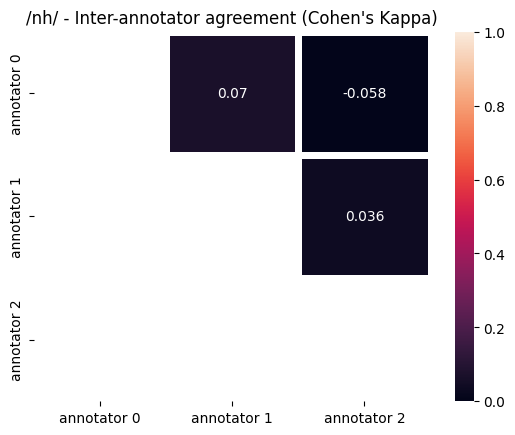

In [9]:
anotadores = [
    nasal_palatal["realizacao_annotator-0"].tolist(),
    nasal_palatal["realizacao_annotator-1"].tolist(),
    nasal_palatal["realizacao_annotator-2"].tolist(),
]

data = np.zeros((len(anotadores), len(anotadores)))

for j, k in list(itertools.combinations(range(len(anotadores)), r=2)):
    data[j, k] = cohen_kappa_score(anotadores[j], anotadores[k])
    print(f"Anotador {j} e {k}: {cohen_kappa_score(anotadores[j], anotadores[k])}")

sns.heatmap(
    data,
    mask=np.tri(len(anotadores)),
    annot=True, linewidths=5,
    vmin=0, vmax=1,
    xticklabels=[f"annotator {k}" for k in range(len(anotadores))],
    yticklabels=[f"annotator {k}" for k in range(len(anotadores))],

)
plt.title("/nh/ - Inter-annotator agreement (Cohen's Kappa)")
plt.savefig('../docs/figures/nh_inter-annotator-agreement.png', bbox_inches='tight')
plt.show()

In [10]:
linhas = []

for col in nasal_palatal.columns:
    if col.startswith('realizacao'):
        display(nasal_palatal[col].value_counts())
        annotator = col.split('_')[-1]
        n_vocalicas = nasal_palatal[col].value_counts().get(0, 0)
        n_consonantais = nasal_palatal[col].value_counts().get(1, 0)
        total = n_vocalicas + n_consonantais
        percent_vocalicas = (n_vocalicas / total) * 100 if total > 0 else 0
        percent_consonantais = (n_consonantais / total) * 100
        
        linhas.append({
            'annotator': annotator,
            'n_consonantais': n_consonantais,
            'percent_consonantais': round(percent_consonantais, 2),
            'n_vocalicas': n_vocalicas,
            'percent_vocalicas': round(percent_vocalicas, 2)
        })

realizacao_annotator-0
1    135
0     18
Name: count, dtype: int64

realizacao_annotator-1
1    88
0    65
Name: count, dtype: int64

realizacao_annotator-2
1    116
0     37
Name: count, dtype: int64

In [11]:
nh_describe = pd.DataFrame(linhas)
nh_describe.head()

,annotator,n_consonantais,percent_consonantais,n_vocalicas,percent_vocalicas
0,annotator-0,135,88.24,18,11.76
1,annotator-1,88,57.52,65,42.48
2,annotator-2,116,75.82,37,24.18


In [12]:
nh_describe.to_csv("../data/finalized/stats_nasal-palatal_stratified_sample.csv", index=False)

## **/lh/ sample**

In [13]:
lateral_palatal = pd.read_csv("../data/finalized/annotated_lh_stratified_sample.csv")
lateral_palatal.info()

<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   entrevista                   80 non-null     str  
 1   trilha                       80 non-null     str  
 2   contexto                     80 non-null     str  
 3   item_lexical                 80 non-null     str  
 4   contexto_anterior            80 non-null     str  
 5   contexto_posterior           80 non-null     str  
 6   tonicidade                   80 non-null     str  
 7   classe_gramatical            80 non-null     str  
 8   deslocamento                 80 non-null     str  
 9   sexo                         80 non-null     str  
 10  tempo_curso                  80 non-null     str  
 11  tempo_ocorrencia             80 non-null     int64
 12  monitoramento                80 non-null     str  
 13  realizacao_annotator-1       80 non-null     int64
 14  numero_

In [14]:
cohens_kappa = calcular_kappa(lateral_palatal, ["realizacao_annotator-0", "realizacao_annotator-1"])
print(f"Cohen's Kappa: {cohens_kappa:.4f}")

Cohen's Kappa: 0.6491


In [15]:
linhas = []

for col in lateral_palatal.columns:
    if col.startswith('realizacao'):
        display(lateral_palatal[col].value_counts())
        annotator = col.split('_')[-1]
        n_naopadrao = lateral_palatal[col].value_counts().get(0, 0)
        n_padrao = lateral_palatal[col].value_counts().get(1, 0)
        total = n_naopadrao + n_padrao
        percent_nao_padrao = (n_naopadrao / total) * 100 if total > 0 else 0
        percent_padrao = (n_padrao / total) * 100
        
        linhas.append({
            'annotator': annotator,
            'n_padrao': n_padrao,
            'percent_padrao': round(percent_padrao, 2),
            'n_nao-padrao': n_naopadrao,
            'percent_nao-padrao': round(percent_nao_padrao, 2)
        })

realizacao_annotator-1
1    74
0     6
Name: count, dtype: int64

realizacao_annotator-0
1    77
0     3
Name: count, dtype: int64

In [16]:
lh_describe = pd.DataFrame(linhas)
lh_describe.head()

,annotator,n_padrao,percent_padrao,n_nao-padrao,percent_nao-padrao
0,annotator-1,74,92.50,6,7.50
1,annotator-0,77,96.25,3,3.75


In [17]:
lh_describe.to_csv("../data/finalized/stats_lateral-palatal_stratified_sample.csv", index=False)